<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML321ENSkillsNetwork817-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **Exploratory Data Analysis on Online Course Enrollment Data**


## Project Overview

This project focuses on performing Exploratory Data Analysis (EDA) on online course enrollment data to identify meaningful patterns, trends and insights related to course popularity and learner interest.

The analysis explores course titles, course categories, rating distributions and enrollment patterns to understand which courses attract the highest level of learner engagement.

Using Python and its data analysis libraries, this project demonstrates how raw datasets can be explored, processed, analysed and transformed into meaningful insights.


## Project Objectives

The main objectives of this project are:

- Explore and understand the structure of the online course datasets.
- Identify frequently occuring keywords in course titles using WordCloud.
- Perform descriptive statistical analysis on course content data.
- Analyse popular course genres and categories.
- Examine course ratings and enrollment patterns.
- Identify the top 20 most popular courses based on rating counts.
- Calculate the percentage contributions of the top 20 courses to the       overall ratings.
- Present findings through appropriate data visualizations.


----


## 1. Environment Setup and Library Imports


This project uses Python and several essential libraries for data manipulation, statistical analysis and data visualization.

The following libraries are used throughout the analysis:


In [1]:
# Run this cell only if the required libraries are not installed.

# %pip install pandas numpy matplotlib seaborn wordcloud

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


and import necessary class/methods in the packages


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator

%matplotlib inline

In [2]:
# Set a random seed for reproducibility
np.random.seed(123)

### Data Loading and Initial Exploration


In this section, the datasets are loaded into Pandas DataFrames for initial exploration and analysis.

The objective is to understand the structure of the datasets, examine the available variables and identify the information that will be used in the subsequent analysis.


In [3]:
# Define the source locations of the datasets
course_genre_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML321EN-SkillsNetwork/labs/datasets/course_genre.csv"
ratings_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMSkillsNetwork-ML0321EN-Coursera/labs/v2/module_3/ratings.csv"

In [4]:
course_df = pd.read_csv(course_genre_url)
ratings_df = pd.read_csv(ratings_url)

We will start by exploring the course genre dataset. Let's first check its columns/features name:


In [5]:
course_df.columns

Index(['COURSE_ID', 'TITLE', 'Database', 'Python', 'CloudComputing',
       'DataAnalysis', 'Containers', 'MachineLearning', 'ComputerVision',
       'DataScience', 'BigData', 'Chatbot', 'R', 'BackendDev', 'FrontendDev',
       'Blockchain'],
      dtype='str')

The course genre dataset contains information about individual courses including their unique course IDs, titles and genre-related attributes.

These genre columns help identify the subject areas covered by each course, such as Python, Data Science, Machine Learning, Cloud Computing and Database Management

This information will help us understand the distribution of course topics and identify popular learning areas in the online education domain.

# Number of Unique Courses

Before proceeding with the analysis, let's determine how many unique courses are available in the dataset. This will help us understand the overall size of the course catalogue


In [6]:
# Count the number of unique courses

course_df['COURSE_ID'].nunique()

307

# Preview of the Dataset

Let's examine the first five records to understand how the course information is organised and how the different features are represented in the dataset.

In [7]:
course_df.head()

,COURSE_ID,TITLE,Database,Python,CloudComputing,DataAnalysis,Containers,MachineLearning,ComputerVision,DataScience,BigData,Chatbot,R,BackendDev,FrontendDev,Blockchain
0,ML0201EN,robots are coming build iot apps with watson ...,0,0,0,0,0,0,0,0,0,0,0,1,1,0
1,ML0122EN,accelerating deep learning with gpu,0,1,0,0,0,1,0,1,0,0,0,0,0,0
2,GPXX0ZG0EN,consuming restful services using the reactive ...,0,0,0,0,0,0,0,0,0,0,0,1,1,0
3,RP0105EN,analyzing big data in r using apache spark,1,0,0,1,0,0,0,0,1,0,1,0,0,0
4,GPXX0Z2PEN,containerizing packaging and running a sprin...,0,0,0,0,1,0,0,0,0,0,0,1,0,0


# Initial Observation

The dataset contains course-related information, including course IDs, course titles and different technology categories such as Python, Database, Data Science and Machine Learning.

From the first five records, we can observe that the technology categories are represented using binary values (0 and 1). This indicates whether a particular course belongs to a specific category.

This initial preview helps us understand the dataset structure before proceeding with further analysis and visualization.

In [9]:
course_df.dtypes

COURSE_ID            str
TITLE                str
Database           int64
Python             int64
CloudComputing     int64
DataAnalysis       int64
Containers         int64
MachineLearning    int64
ComputerVision     int64
DataScience        int64
BigData            int64
Chatbot            int64
R                  int64
BackendDev         int64
FrontendDev        int64
Blockchain         int64
dtype: object

## Understanding the Data Types

The data type inspection shows that the COURSE_ID and TITLE columns contain string values while all the course genre columns are stored as integers(int64).

The genre columns use binary encoding:

- 1 indicates that a course belongs to a particular genre.
- 0 indicates that the course is not associated with that genre.

For example, the course titled "accelerating deep learning with GPU" is associated with Python, Machine Learning and Data Science as indicated by the value 1 in those respective columns.

Understanding these data types and encoding methods will help us perform accurate data manipulation and further analysis.

In [8]:
course_df.iloc[1, ]

COURSE_ID                                     ML0122EN
TITLE              accelerating deep learning with gpu
Database                                             0
Python                                               1
CloudComputing                                       0
DataAnalysis                                         0
Containers                                           0
MachineLearning                                      1
ComputerVision                                       0
DataScience                                          1
BigData                                              0
Chatbot                                              0
R                                                    0
BackendDev                                           0
FrontendDev                                          0
Blockchain                                           0
Name: 1, dtype: object

## Example of Course Genre Classification

To understand the binary encoding more clearly, we examined the second record of the dataset using the iloc method.

The course titled "accelerating deep learning with GPU" has a value of 1 for Python, Machine Learning and Data Science. This indicates that the course is associated with these three categories.

The remaining genre columns have a value of 0, meaning that the course is not classified under those categories.

This example confirms how multiple technology categories are represented within a single course record.

## Text Analysis of Course Titles

In this section, we will analyse the course titles to identify frequently occuring keywords. These keywords can help us understand the major subject areas and technical topics covered by the courses in the dataset.

### Plot a Word Cloud from Course Titles


To prepare the text for visualization, we first combine all course titles into a single string. This allows us to analyse the words collectively and generate a word cloud.

In [9]:
titles = " ".join(title for title in course_df['TITLE'].astype(str))

In [12]:
titles

'robots are coming  build iot apps with watson  swift  and node red accelerating deep learning with gpu consuming restful services using the reactive jax rs client analyzing big data in r using apache spark containerizing  packaging  and running a spring boot application cloud native security conference  data security data science bootcamp with r for university proffesors learn how to use docker containers for iterative development scorm test course create your first mongodb database testing microservices with the arquillian managed container cloud pak for integration essentials watson analytics for social media data science bootcamp with python for university professors  advance create a cryptocurrency trading algorithm in python data   ai essentials securing java microservices with eclipse microprofile json web token  microprofile jwt  enabling distributed tracing in microservices with zipkin sql access for hadoop ybrid cloud conference  ai pipelines lab dataops methodology data   ai

## Text Cleaning and Stopword Removal

Before generating the word cloud, we need to remove common English stopwords and other frequently occuring words that do not provide meaningful information about the course topics.

We will also add some dataset-specific terms to the stopword list to make the final visualization more focused on relevant technical keywords.

In [13]:
# English Stopwords
stopwords = set(STOPWORDS)
stopwords.update(["getting started", "using", "enabling", "template", "university", "end", "introduction", "basic"])

Then, we create a ```WordCloud``` object and generate ```wordcloud``` from the titles.


In [14]:
wordcloud = WordCloud(stopwords=stopwords, background_color="white", width=800, height=400)

In [15]:
wordcloud.generate(titles)

We can use `plt.imshow()` method to visualize the generated wordcloud:


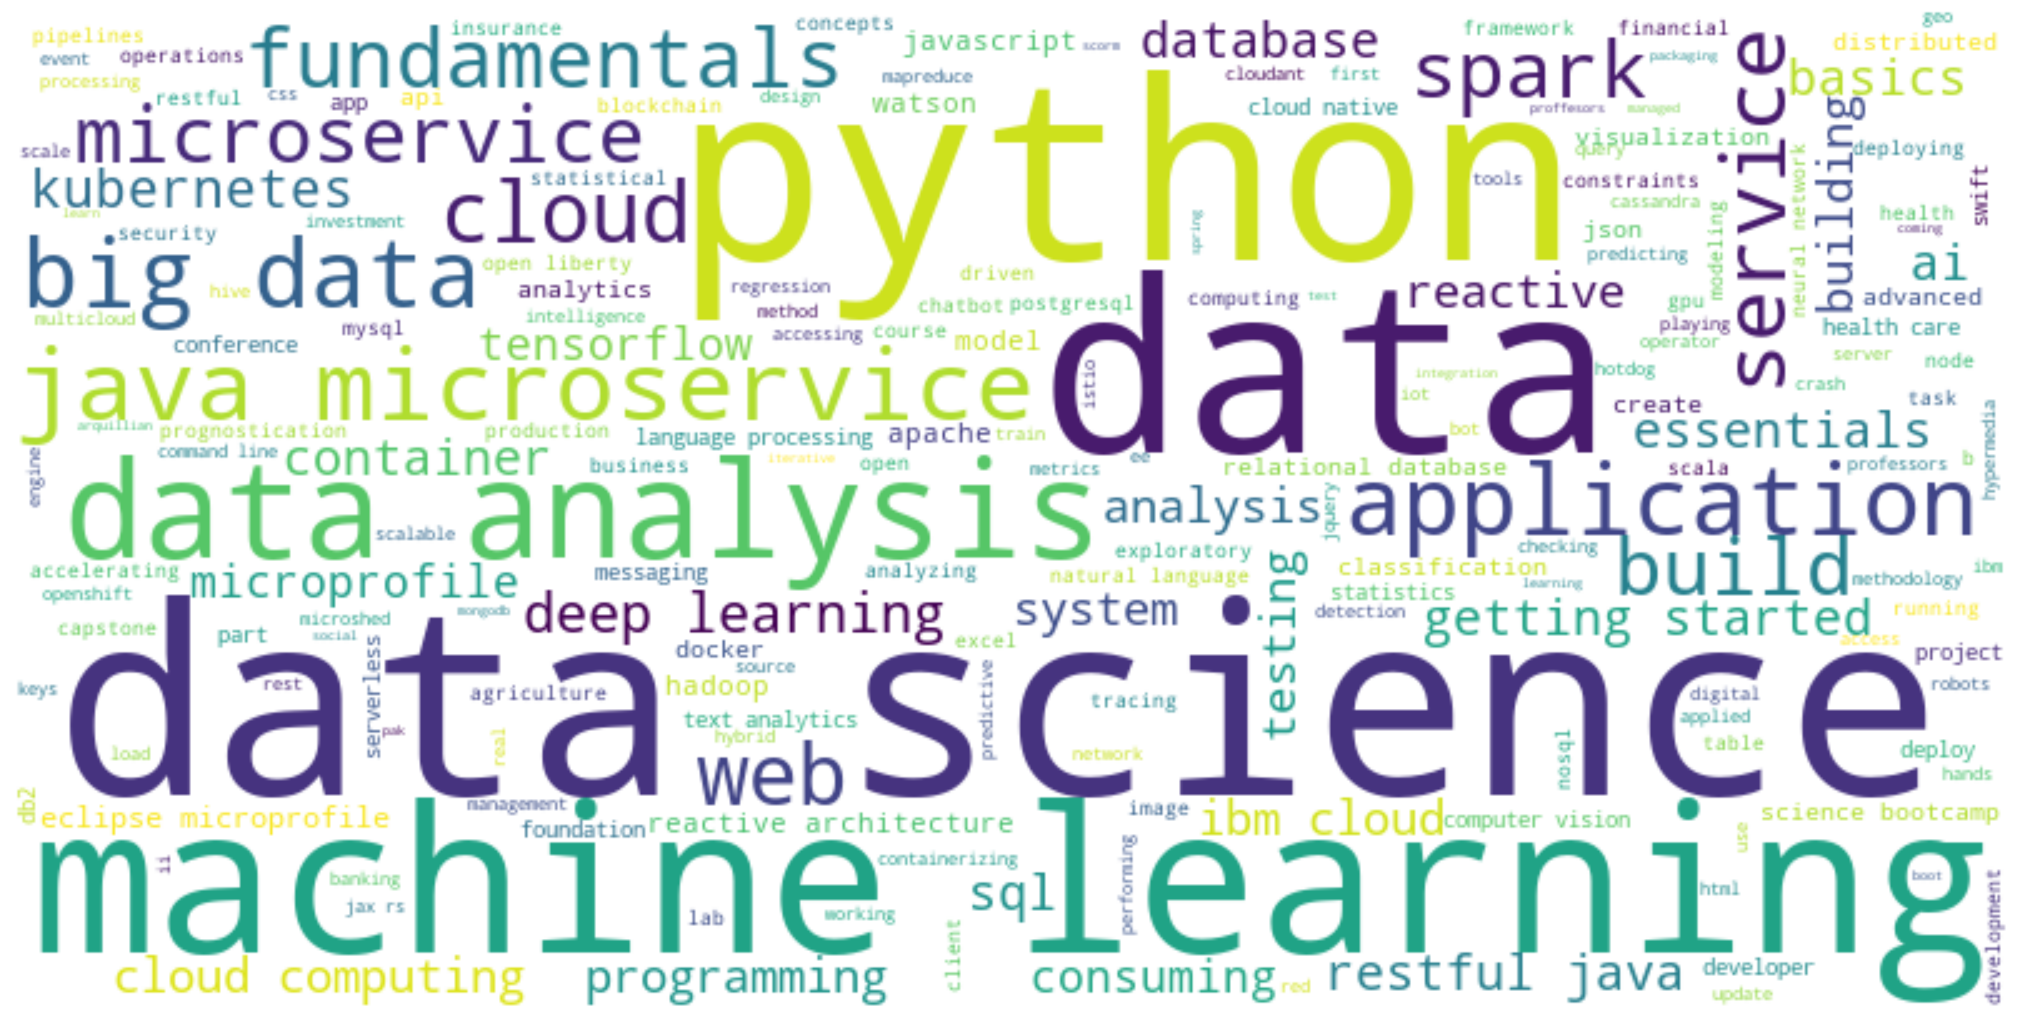

In [16]:
# Create a new figure with a specified size
plt.figure(figsize=(20, 10))

# Disable axis display
plt.axis("off")

# Display the word cloud image with bilinear interpolation
plt.imshow(wordcloud, interpolation='bilinear')

# Adjust the layout to ensure tight spacing
plt.tight_layout(pad=0)

# Show the plot
plt.show()

The word cloud highlights the most frequently occuring keywords in the course titles. Terms such as Python, Data Science, Machine Learning, Data Analysis, Big Data and AI appear prominently.

This suggests that the dataset contains a strong focus on technology- related courses and in-demand IT skills. These observations will help us understand the course offerings and explore their distribution in the upcoming analysis.

### Analyze Course Genres


In this section, we will explore different course genres and identify courses that may be of interest to us.

For example, we will start by identifying all courses related to Machine Learning.

_Task: Find all courses with genre `MachineLearning` == 1_


In [17]:
course_df[course_df['MachineLearning'] == 1]


,COURSE_ID,TITLE,Database,Python,CloudComputing,DataAnalysis,Containers,MachineLearning,ComputerVision,DataScience,BigData,Chatbot,R,BackendDev,FrontendDev,Blockchain
1,ML0122EN,accelerating deep learning with gpu,0,1,0,0,0,1,0,1,0,0,0,0,0,0
15,DAI101EN,data ai essentials,0,0,0,0,0,1,0,0,0,0,0,0,0,0
19,HCC105EN,ybrid cloud conference ai pipelines lab,0,0,0,0,0,1,0,0,0,0,0,0,0,0
21,DS0132EN,data ai jumpstart your journey,0,0,0,0,0,1,0,0,0,0,0,0,0,0
24,BENTEST4,ai for everyone master the basics,0,0,0,0,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274,excourse61,convolutional neural networks in tensorflow,0,0,0,0,0,1,1,0,0,0,0,0,0,0
282,excourse69,machine learning with big data,0,0,0,0,0,1,0,0,1,0,0,0,0,0
290,excourse77,natural language processing with attention models,0,0,0,0,0,1,0,0,0,0,0,0,0,0
291,excourse78,natural language processing with sequence models,0,0,0,0,0,1,0,0,0,0,0,0,0,0


<details>
    <summary>Click here for Hints</summary>
    
You can find the indexes of all courses with genre `MachineLearning` == 1 by using: 
    
```python
course_df['MachineLearning'] == 1
```
Then you can find the courses by using the indexes:
    
```python
ml_courses = course_df[indexes]
```
</details>


## Finding Scalable Machine Learning Courses

Next, let's identify courses that are related to both Machine Learning and Big Data. This will help us find courses that focus on scalable machine learning technologies.

_Task: Find all courses with genres `MachineLearning` == 1 and `BigData` == 1_


In [18]:
course_df[
    (course_df['MachineLearning'] == 1) &
    (course_df['BigData'] == 1)
]


,COURSE_ID,TITLE,Database,Python,CloudComputing,DataAnalysis,Containers,MachineLearning,ComputerVision,DataScience,BigData,Chatbot,R,BackendDev,FrontendDev,Blockchain
46,GPXX0BUBEN,insurance risk assessment with montecarlo meth...,0,0,0,0,0,1,0,0,1,0,0,0,0,0
59,TA0106EN,text analytics at scale,0,0,0,0,0,1,0,1,1,0,0,0,0,0
184,BD0221EN,spark mllib,0,0,0,0,0,1,0,0,1,0,0,0,0,0
282,excourse69,machine learning with big data,0,0,0,0,0,1,0,0,1,0,0,0,0,0


<details>
    <summary>Click here for Hints</summary>

You can find them by using previously found dataset of all courses with genre `MachineLearning` == 1_ and finding all courses with `BigData` == 1_ . Indexes can be found by using:
    
    
```python
mouse_df['BigData'] == 1
```


In [19]:
genres = course_df.columns[2:]
genres

Index(['Database', 'Python', 'CloudComputing', 'DataAnalysis', 'Containers',
       'MachineLearning', 'ComputerVision', 'DataScience', 'BigData',
       'Chatbot', 'R', 'BackendDev', 'FrontendDev', 'Blockchain'],
      dtype='str')

## Course Genre Analysis

Now, let's calculate the number of courses available in each game. This will help us understand which topics are most popular in the dataset.

For example, Machine Learning has 69 courses while Python has 28 courses.

We will also sort the results in descending order to identify the most popular course games.

Task: Use Pandas sum() and sort_values() methods to calculate and sort the course count for each game.

In [20]:
course_df.iloc[:, 2:].sum().sort_values(ascending=False)



BackendDev         78
MachineLearning    69
Database           60
DataAnalysis       56
DataScience        38
CloudComputing     37
BigData            36
Python             28
FrontendDev        19
Containers         17
R                  17
ComputerVision     10
Chatbot             4
Blockchain          4
dtype: int64

<details>
    <summary>Click here for Hints</summary>

You can use `course_df[genres].sum(axis=0)` to sum the values, then use `pd.DataFrame(genre_sums, columns = ['Count'])` to convert it into a data frame, apply `.sort_values(by = "Count", ascending=False)` on the resulted course count data set to sort it.


We can also visualize course genre counts using a bar chart:


_Task: Use seaborn barplot or other plot methods to plot course genre counts using a barchart. The x-axis is the course genre and the y-axis is the course count per genre._


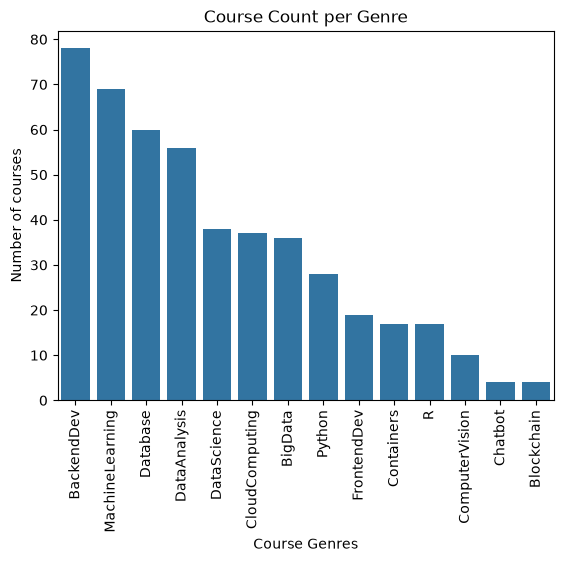

In [20]:
genre_sums = course_df.iloc[:, 2:].sum().sort_values(ascending=False)

genre_sums = genre_sums.to_frame(name="Count")

plot = sns.barplot(x=genre_sums.index, y="Count", data=genre_sums)

plt.xticks(rotation=90)
plt.title("Course Count per Genre")
plt.xlabel("Course Genres")
plt.ylabel("Number of courses")

plt.show()

<details>
    <summary>Click here for Hints</summary>
    
You can use `sns.barplot(x=genre_sums.index, y="Count", data=genre_sums)` to create your plot. you can rotate your labels by using `plot.set_xticklabels(plot.get_xticklabels(),rotation = 90)` method.


At this point, we have developed a good understanding of the course metadata including keywords in course titles and the distribution of popular course genres. Next, we will move on to exploring the course learner-related datasets.

###  TASK: Analyze Course Enrollments


Let's first take a look at the course enrollments dataset.


In [21]:
ratings_df.head()

,user,item,rating
0,1889878,CC0101EN,5
1,1342067,CL0101EN,3
2,1990814,ML0120ENv3,5
3,380098,BD0211EN,5
4,779563,DS0101EN,3


The dataset contains three columns: user, which represents the user ID, item, which represents the course ID and rating, which represents the rating given by the user to the course.

In [22]:
ratings_df['rating'].unique()

array([5, 3, 4])

The **rating** column contains three possible values: 3, 4, 5.

- 5: Excellent - The user is highly satisfied with the course. 

- 4: Good - The user is satisfied with the course.

- 3: Below expectations - The course needs improvement.

Let's see how many ratings we have in the dataset:


In [23]:
ratings_df.shape[0]

233306

We have 233306 enrollments. In fact, each user is likely to interact with multiple items so let's find the rating counts for each user:


In [24]:
user_rating_counts = ratings_df.groupby('user').size()

user_rating_counts

user
2          61
4          44
5          59
7           1
8           3
           ..
2102054     8
2102356     1
2102680    11
2102983     1
2103039     1
Length: 33901, dtype: int64

<details>
    <summary>Click here for Hints</summary>
    
You can use `ratings_df.groupby('user')` to group by `user` and then `.size()` method to aggregate the rating count 


After grouping the data by user, we can calculate some summary statistics to understand how frequently users interact with courses. For example, user 4 rated 44 courses while user 2 rated 61 users.

In [25]:
user_rating_counts.describe()


count    33901.000000
mean         6.881980
std          5.823548
min          1.000000
25%          2.000000
50%          6.000000
75%          9.000000
max         61.000000
dtype: float64

We can also use a histogram to visualize the distribution of user ratings. It helps us understand how many users rated a small number of courses and how many users rated a larger number of courses.

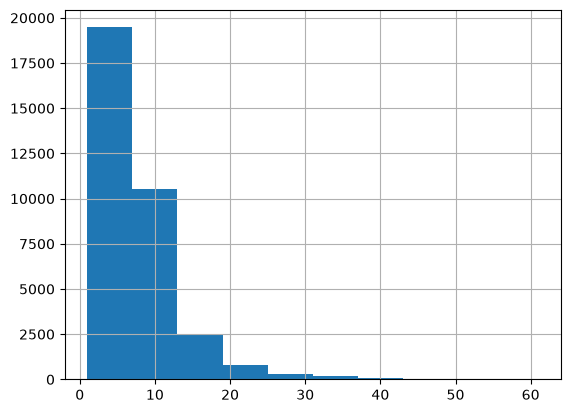

In [26]:
user_rating_counts.hist()

plt.show()


From this histogram, we can observe that most users have rated only a small number of courses. As the number of ratings increases, the number of users gradually decreases. This indicates that only a smaller group of users actively rates a large number of courses.

<details>
    <summary>Click here for Hints</summary>
    
You can use `.hist()` command on yout data set


### Task: Find the Top-20 Most Popular Courses


Now we know how many items each user rated. Let's identify the 20 most popular courses based on the number of ratings they received.

_TODO: Use Pandas groupby() and size() methods on the item column to aggregate the rating count for each item, then use the sort_values() method to sort the course enrollment count, and use the slice method to get the top 20 courses. You may also implement this task with different solutions_


In [27]:
top_20_courses = ratings_df.groupby(['item']).size().reset_index()

top_20_courses.columns = ['course', 'Ratings']

top_20_courses = top_20_courses.sort_values(
    by='Ratings',
    ascending=False
).reset_index(drop=True)

top_20_courses = top_20_courses.head(20)

The results currently show only course IDs which do not tell us the actual course names.

To make the results easier to understand, we will join the course metadata dataset (course_df) to retrieve the actual course titles.

In [28]:
top_20_courses = ratings_df.groupby(['item']).size().reset_index()

top_20_courses.columns = ['course', 'Ratings']

top_20_courses = top_20_courses.sort_values(
    by='Ratings',
    ascending=False
).reset_index(drop=True)

top_20_courses = top_20_courses.head(20)


top_20_courses = pd.merge(
    top_20_courses,
    course_df[['COURSE_ID', 'TITLE']],
    how='left',
    left_on='course',
    right_on='COURSE_ID'
)

top_20_courses = top_20_courses[['TITLE', 'Ratings']]

top_20_courses


,TITLE,Ratings
0,python for data science,14936
1,introduction to data science,14477
2,big data 101,13291
3,hadoop 101,10599
4,data analysis with python,8303
5,data science methodology,7719
6,machine learning with python,7644
7,spark fundamentals i,7551
8,data science hands on with open source tools,7199
9,blockchain essentials,6719


Your list of the 20 most-rated courses may look like this:

In [33]:
# Get the total number of ratings again
total = ratings_df.shape[0]
total

233306

In [30]:
top = 0

In [31]:
top = sum(top_20_courses['Ratings'].values)

percentage = (top / total) * 100

percentage


np.float64(63.30227255192751)

In [34]:
print(f"Percentage of ratings received by the top 20 courses: {round((top * 100)/total, 2)}%")

Percentage of ratings received by the top 20 courses: 63.3%


## Conclusion and Key Findings

In this project, I performed an exploratory data analysis (EDA) on course metadata and learner rating datasets using Python. The main objective was to understand course popularity, identify popular genres and explore learner rating patterns.

## Key Findings

Course Genre Analysis: Backend Development emerged as the most popular genre with 78 courses, followed by Machine Learning with 69 courses, Database with 60 courses, and Data Analysis with 56 courses.

Popular Courses: By analyzing the rating counts, I identified the top 20 most-rated courses. These courses collectively received approximately 63.3% of all ratings in the dataset.

User Rating Behaviour: The analysis showed that most users rated a relatively small number of courses. The average number of ratings per user was approximately 6.88, while the median was 6.

Data Visualization: Bar charts and histograms helped visualize course genre distribution and user rating patterns, making the findings easier to understand.

## Learning Outcomes

Through this project, I gained practical experience in:

Data exploration and analysis using Pandas.

Grouping, aggregation and sorting operations.

Extracting meaningful insights from datasets.

Data visualization using Matplotlib and Seaborn.

Understanding user rating patterns and course popularity.

## Final Remarks

This project helped me understand how exploratory data analysis can be used to identify patterns and extract meaningful insights from real-world datasets. It also improved my practical knowledge of Python and its data analysis libraries.

Tools and Technologies: Python, Pandas, NumPy, Matplotlib and Seaborn.